# Livestock Adaptive Procurement Optimizer
### Compare fixed reorder policy vs disruption-aware adaptive policy

This notebook tests whether an adaptive procurement policy can reduce shortages during price shocks and supplier delays.

**Important scope notes**
- This is an operational simulation using clearly labelled synthetic ingredient demand, stock, prices, and lead times.
- It is not a validated cattle ration or a real-farm performance claim.
- The previous scenario-testing ZIP is optional input for reference; this notebook independently reruns the scenarios with a fixed policy and an adaptive policy under the same assumptions.
- Nutrient constraints and animal-specific requirements are not optimized in this stage. This is procurement/inventory optimization only.

## 1. Setup and optional input discovery

Attach the previous results dataset in Kaggle if you want the notebook to find and summarize the previous scenario output. This new simulation does not require it to run.

In [1]:
from pathlib import Path
import os, zipfile, shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working/livestock_adaptive_procurement")
WORK_ROOT.mkdir(parents=True, exist_ok=True)

print("Attached files (if any):")
found = []
if INPUT_ROOT.exists():
    for p in INPUT_ROOT.rglob("*"):
        if p.is_file():
            found.append(p)
            print(p)

previous_comparison = None
for p in found:
    if p.name.lower() == "scenario_comparison.csv":
        try:
            previous_comparison = pd.read_csv(p)
            print("\nPrevious scenario comparison found:", p)
            display(previous_comparison.head())
            break
        except Exception as e:
            print("Could not read previous comparison:", e)

if previous_comparison is None:
    print("\nNo previous scenario_comparison.csv found. That's okay; this notebook runs independently.")

Attached files (if any):
/kaggle/input/datasets/shyaamsundar19/livestock-stress/scenario_daily_inventory.csv
/kaggle/input/datasets/shyaamsundar19/livestock-stress/README_scenario_testing.txt
/kaggle/input/datasets/shyaamsundar19/livestock-stress/scenario_ingredient_summary.csv
/kaggle/input/datasets/shyaamsundar19/livestock-stress/scenario_comparison.csv

Previous scenario comparison found: /kaggle/input/datasets/shyaamsundar19/livestock-stress/scenario_comparison.csv


,scenario,estimated_30d_feed_cost_inr,total_stockout_days_across_ingredients,total_unmet_demand_kg,total_orders_placed,cost_change_vs_baseline_inr,cost_change_vs_baseline_pct
0,baseline,3435.398230,0,0.0,7,0.000000,0.0
1,combined,4122.477876,6,30.0,6,687.079646,20.0
2,price_shock,4122.477876,0,0.0,7,687.079646,20.0
3,supplier_delay,3435.398230,6,30.0,6,0.000000,0.0


In [9]:
# Create the fixed-vs-adaptive comparison table
comparison_rows = []

for scenario in summary["scenario"].unique():
    part = summary[summary["scenario"] == scenario].set_index("policy")

    fixed = part.loc["fixed"]
    adaptive = part.loc["adaptive"]

    comparison_rows.append({
        "scenario": scenario,
        "fixed_cost": fixed["procurement_cost"],
        "adaptive_cost": adaptive["procurement_cost"],
        "cost_change_adaptive_minus_fixed":
            adaptive["procurement_cost"] - fixed["procurement_cost"],
        "fixed_stockout_ingredient_days":
            fixed["stockout_ingredient_days"],
        "adaptive_stockout_ingredient_days":
            adaptive["stockout_ingredient_days"],
        "fixed_unmet_demand_kg": fixed["unmet_demand_kg"],
        "adaptive_unmet_demand_kg": adaptive["unmet_demand_kg"],
        "unmet_demand_reduction_kg":
            fixed["unmet_demand_kg"] - adaptive["unmet_demand_kg"],
        "fixed_order_count": fixed["order_count"],
        "adaptive_order_count": adaptive["order_count"],
    })

policy_comparison = pd.DataFrame(comparison_rows)

display(policy_comparison)

,scenario,fixed_cost,adaptive_cost,cost_change_adaptive_minus_fixed,fixed_stockout_ingredient_days,adaptive_stockout_ingredient_days,fixed_unmet_demand_kg,adaptive_unmet_demand_kg,unmet_demand_reduction_kg,fixed_order_count,adaptive_order_count
0,baseline,5244.0,5244.0,0.0,0,0,0.0,0.0,0.0,35,35
1,combined_disruption,6196.8,7032.0,835.2,6,3,34.0,19.0,15.0,34,87
2,price_shock,6292.8,6292.8,0.0,0,0,0.0,0.0,0.0,35,35
3,supplier_delay,5164.0,5860.0,696.0,6,3,34.0,19.0,15.0,34,87


## 2. Define the simulation assumptions

These values are **illustrative**, not measured farm data. You can change them and rerun the notebook. The same demand and starting stock are used for both policies in each scenario.

In [2]:
# Synthetic ingredients: daily demand in kg, starting stock in kg, base price per kg,
# and normal supplier lead time in days.
ingredients = pd.DataFrame([
    {"ingredient": "Green fodder", "daily_demand_kg": 10.0, "initial_stock_kg": 35.0, "base_price_per_kg": 8.0, "base_lead_days": 2},
    {"ingredient": "Dry fodder",   "daily_demand_kg": 4.0,  "initial_stock_kg": 20.0, "base_price_per_kg": 6.0, "base_lead_days": 3},
    {"ingredient": "Concentrate",  "daily_demand_kg": 3.0,  "initial_stock_kg": 18.0, "base_price_per_kg": 22.0, "base_lead_days": 2},
])

SIM_DAYS = 30
PRICE_SHOCK = 0.20
DELAY_EXTRA_DAYS = 3

# Policy settings:
# Fixed policy: reorder point based on normal lead time + 2 safety days.
# Adaptive policy: increases reorder point and target stock when lead time is disrupted.
FIXED_SAFETY_DAYS = 2
ADAPTIVE_EXTRA_SAFETY_DAYS = 2
FIXED_TARGET_COVER_DAYS = 7
ADAPTIVE_TARGET_COVER_DAYS = 10

display(ingredients)
print(f"Simulation horizon: {SIM_DAYS} days")
print("All ingredient values above are synthetic demo assumptions.")

,ingredient,daily_demand_kg,initial_stock_kg,base_price_per_kg,base_lead_days
0,Green fodder,10.0,35.0,8.0,2
1,Dry fodder,4.0,20.0,6.0,3
2,Concentrate,3.0,18.0,22.0,2


Simulation horizon: 30 days
All ingredient values above are synthetic demo assumptions.


## 3. Simulation engine

Policy definitions:
- **Fixed reorder policy:** keeps the same reorder point even when supplier lead times increase.
- **Adaptive policy:** recalculates the reorder point using the scenario's longer lead time and adds extra safety stock during delays. It also targets more days of stock cover during a delay.
- Replenishment orders arrive after the scenario-specific lead time. Orders are placed when inventory position (on-hand stock plus outstanding orders) reaches the reorder point.
- Daily unmet demand is recorded if available stock is insufficient.

In [3]:
def simulate_policy(policy_name, scenario_name, price_multiplier=1.0, extra_lead_days=0):
    rows = []
    order_rows = []

    for _, item in ingredients.iterrows():
        name = item["ingredient"]
        demand = float(item["daily_demand_kg"])
        stock = float(item["initial_stock_kg"])
        base_price = float(item["base_price_per_kg"])
        normal_lead = int(item["base_lead_days"])
        lead = normal_lead + int(extra_lead_days)
        price = base_price * float(price_multiplier)

        if policy_name == "fixed":
            reorder_point = demand * (normal_lead + FIXED_SAFETY_DAYS)
            target_stock = demand * FIXED_TARGET_COVER_DAYS
        elif policy_name == "adaptive":
            safety_days = FIXED_SAFETY_DAYS
            target_days = FIXED_TARGET_COVER_DAYS
            if extra_lead_days > 0:
                safety_days += ADAPTIVE_EXTRA_SAFETY_DAYS
                target_days = ADAPTIVE_TARGET_COVER_DAYS
            reorder_point = demand * (lead + safety_days)
            target_stock = demand * target_days
        else:
            raise ValueError("policy_name must be 'fixed' or 'adaptive'")

        # Each pending order is [arrival_day, quantity, unit_price].
        pending = []
        on_order_kg = 0.0

        for day in range(1, SIM_DAYS + 1):
            # Receive orders arriving today.
            arrived_today = 0.0
            still_pending = []
            for arrival_day, qty, order_price in pending:
                if arrival_day <= day:
                    arrived_today += qty
                    on_order_kg -= qty
                else:
                    still_pending.append([arrival_day, qty, order_price])
            pending = still_pending
            stock += arrived_today

            stock_at_start = stock
            consumed = min(stock, demand)
            unmet = max(0.0, demand - stock)
            stock -= consumed

            # Reorder based on inventory position after today's consumption.
            inventory_position = stock + on_order_kg
            order_qty = 0.0
            if inventory_position <= reorder_point:
                order_qty = max(0.0, target_stock - inventory_position)
                if order_qty > 0:
                    arrival_day = day + max(1, lead)
                    pending.append([arrival_day, order_qty, price])
                    on_order_kg += order_qty
                    order_rows.append({
                        "scenario": scenario_name,
                        "policy": policy_name,
                        "ingredient": name,
                        "order_day": day,
                        "arrival_day": arrival_day,
                        "quantity_kg": order_qty,
                        "unit_price": price,
                        "order_cost": order_qty * price,
                    })

            rows.append({
                "scenario": scenario_name,
                "policy": policy_name,
                "day": day,
                "ingredient": name,
                "stock_at_start_kg": stock_at_start,
                "demand_kg": demand,
                "consumed_kg": consumed,
                "unmet_demand_kg": unmet,
                "ending_stock_kg": stock,
                "on_order_kg": on_order_kg,
                "reorder_point_kg": reorder_point,
                "order_qty_kg": order_qty,
                "lead_time_days": lead,
                "unit_price": price,
            })

    return pd.DataFrame(rows), pd.DataFrame(order_rows)

## 4. Run the four disruption scenarios

We compare both policies under:
1. Baseline supply
2. 20% ingredient price increase
3. Three-day supplier delay
4. Combined price increase and delay

This is a controlled comparison: both policies experience the same scenario.

In [4]:
scenarios = [
    {"scenario": "baseline", "price_multiplier": 1.0, "extra_lead_days": 0},
    {"scenario": "price_shock", "price_multiplier": 1.0 + PRICE_SHOCK, "extra_lead_days": 0},
    {"scenario": "supplier_delay", "price_multiplier": 1.0, "extra_lead_days": DELAY_EXTRA_DAYS},
    {"scenario": "combined_disruption", "price_multiplier": 1.0 + PRICE_SHOCK, "extra_lead_days": DELAY_EXTRA_DAYS},
]

daily_parts, order_parts = [], []
for sc in scenarios:
    for policy in ["fixed", "adaptive"]:
        daily_df, orders_df = simulate_policy(
            policy,
            sc["scenario"],
            price_multiplier=sc["price_multiplier"],
            extra_lead_days=sc["extra_lead_days"],
        )
        daily_parts.append(daily_df)
        if not orders_df.empty:
            order_parts.append(orders_df)

daily_results = pd.concat(daily_parts, ignore_index=True)
orders_results = pd.concat(order_parts, ignore_index=True) if order_parts else pd.DataFrame(
    columns=["scenario", "policy", "ingredient", "order_day", "arrival_day", "quantity_kg", "unit_price", "order_cost"]
)

print("Daily simulation rows:", len(daily_results))
print("Order records:", len(orders_results))
display(daily_results.head())
display(orders_results.head())

Daily simulation rows: 720
Order records: 382


,scenario,policy,day,ingredient,stock_at_start_kg,demand_kg,consumed_kg,unmet_demand_kg,ending_stock_kg,on_order_kg,reorder_point_kg,order_qty_kg,lead_time_days,unit_price
0,baseline,fixed,1,Green fodder,35.0,10.0,10.0,0.0,25.0,45.0,40.0,45.0,2,8.0
1,baseline,fixed,2,Green fodder,25.0,10.0,10.0,0.0,15.0,45.0,40.0,0.0,2,8.0
2,baseline,fixed,3,Green fodder,60.0,10.0,10.0,0.0,50.0,0.0,40.0,0.0,2,8.0
3,baseline,fixed,4,Green fodder,50.0,10.0,10.0,0.0,40.0,30.0,40.0,30.0,2,8.0
4,baseline,fixed,5,Green fodder,40.0,10.0,10.0,0.0,30.0,30.0,40.0,0.0,2,8.0


,scenario,policy,ingredient,order_day,arrival_day,quantity_kg,unit_price,order_cost
0,baseline,fixed,Green fodder,1,3,45.0,8.0,360.0
1,baseline,fixed,Green fodder,4,6,30.0,8.0,240.0
2,baseline,fixed,Green fodder,7,9,30.0,8.0,240.0
3,baseline,fixed,Green fodder,10,12,30.0,8.0,240.0
4,baseline,fixed,Green fodder,13,15,30.0,8.0,240.0


## 5. Summarize outcomes and compare policies

Total procurement cost counts orders placed during the 30-day horizon. Orders arriving after day 30 are still counted as purchases; ending inventory and outstanding orders are reported separately so the cost comparison is interpretable.

In [6]:
# Summarize daily inventory outcomes
summary = (
    daily_results.groupby(["scenario", "policy"], as_index=False)
    .agg(
        stockout_ingredient_days=("unmet_demand_kg", lambda s: int((s > 0).sum())),
        unmet_demand_kg=("unmet_demand_kg", "sum"),
        total_consumed_kg=("consumed_kg", "sum"),
        ending_stock_kg=("ending_stock_kg", "last"),
    )
)

# Safely summarize orders, including when no orders exist
if not orders_results.empty:
    costs = (
        orders_results.groupby(["scenario", "policy"], as_index=False)
        .agg(
            procurement_cost=("order_cost", "sum"),
            order_count=("quantity_kg", "size"),
        )
    )
else:
    costs = pd.DataFrame(columns=[
        "scenario", "policy", "procurement_cost", "order_count"
    ])

summary = summary.merge(costs, on=["scenario", "policy"], how="left")
summary["procurement_cost"] = summary["procurement_cost"].fillna(0.0)
summary["order_count"] = summary["order_count"].fillna(0).astype(int)

display(summary.sort_values(["scenario", "policy"]))

,scenario,policy,stockout_ingredient_days,unmet_demand_kg,total_consumed_kg,ending_stock_kg,procurement_cost,order_count
0,baseline,adaptive,0,0.0,510.0,9.0,5244.0,35
1,baseline,fixed,0,0.0,510.0,9.0,5244.0,35
2,combined_disruption,adaptive,3,19.0,491.0,15.0,7032.0,87
3,combined_disruption,fixed,6,34.0,476.0,0.0,6196.8,34
4,price_shock,adaptive,0,0.0,510.0,9.0,6292.8,35
5,price_shock,fixed,0,0.0,510.0,9.0,6292.8,35
6,supplier_delay,adaptive,3,19.0,491.0,15.0,5860.0,87
7,supplier_delay,fixed,6,34.0,476.0,0.0,5164.0,34


## 6. Visualize the comparison

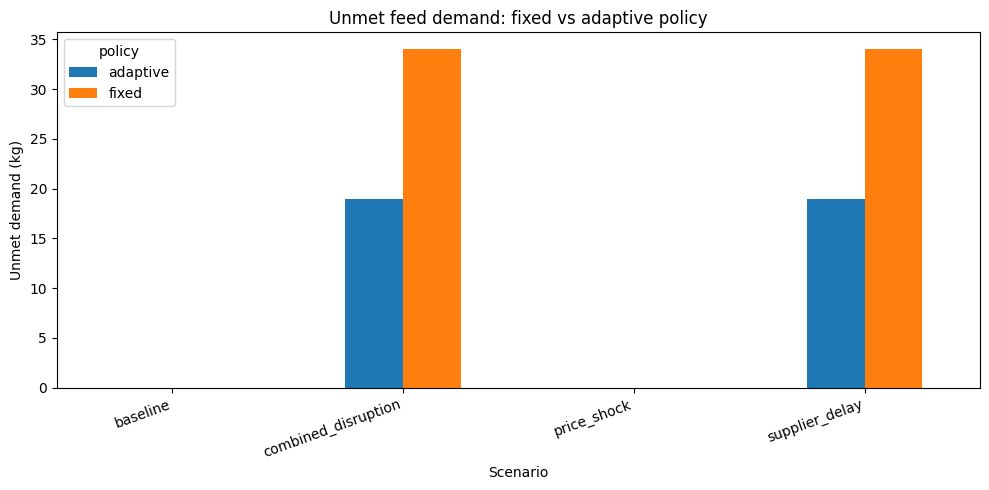

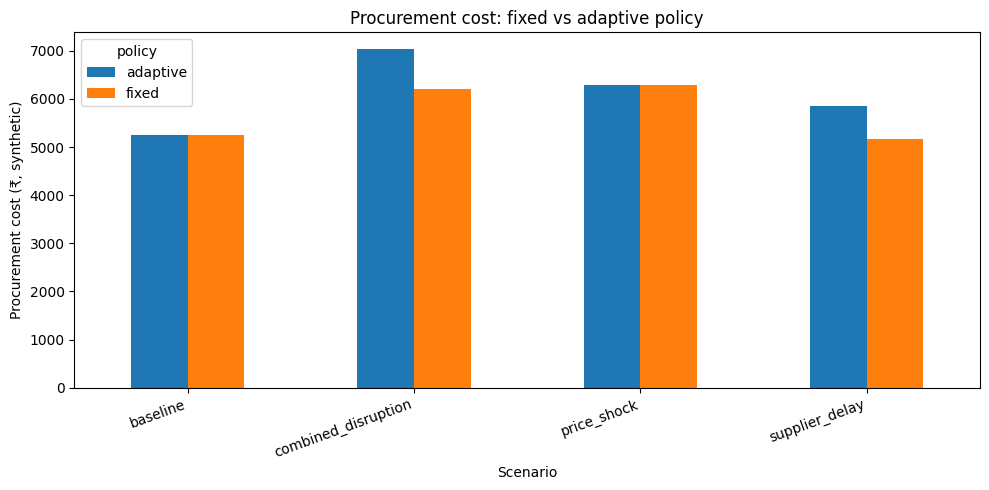

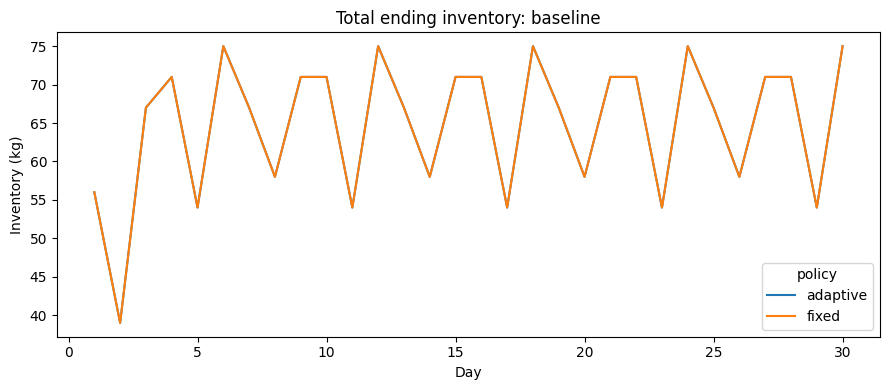

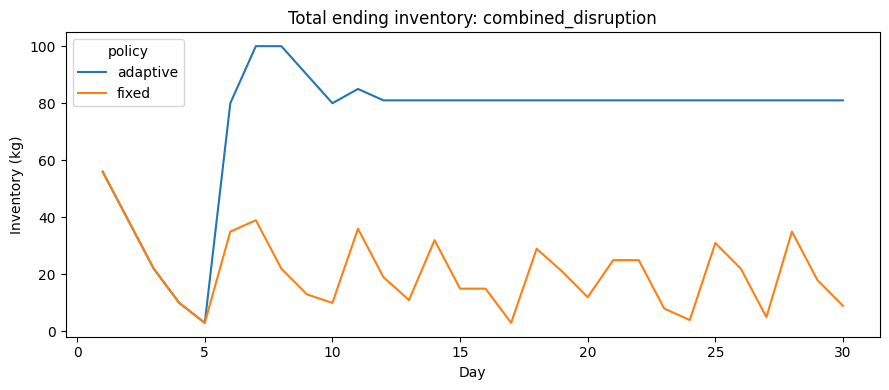

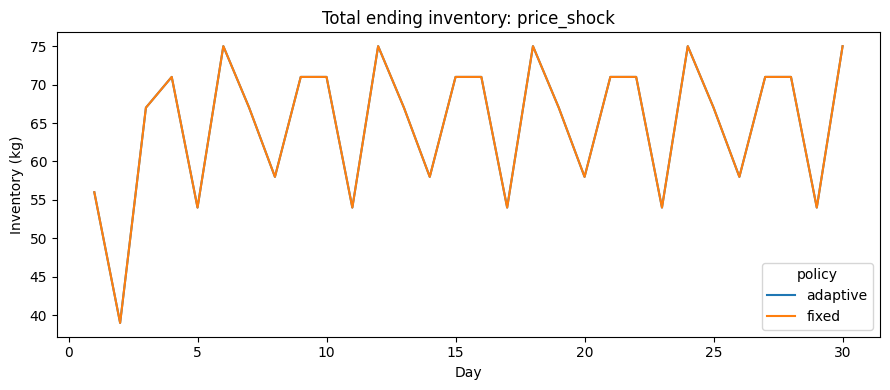

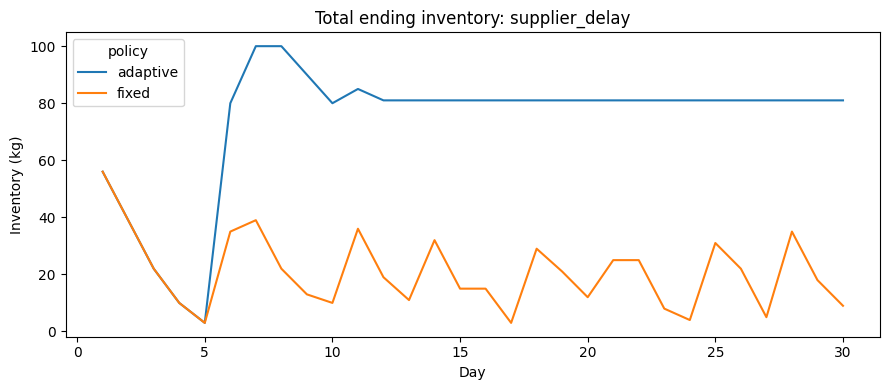

In [7]:
# Unmet demand by scenario and policy
plot_data = summary.pivot(index="scenario", columns="policy", values="unmet_demand_kg")
ax = plot_data.plot(kind="bar", figsize=(10, 5))
ax.set_title("Unmet feed demand: fixed vs adaptive policy")
ax.set_ylabel("Unmet demand (kg)")
ax.set_xlabel("Scenario")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Procurement cost by scenario and policy
plot_cost = summary.pivot(index="scenario", columns="policy", values="procurement_cost")
ax = plot_cost.plot(kind="bar", figsize=(10, 5))
ax.set_title("Procurement cost: fixed vs adaptive policy")
ax.set_ylabel("Procurement cost (₹, synthetic)")
ax.set_xlabel("Scenario")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Daily total inventory trajectory for each scenario and policy
inventory_trend = (
    daily_results.groupby(["scenario", "policy", "day"], as_index=False)
    .agg(total_ending_stock_kg=("ending_stock_kg", "sum"))
)
for scenario in inventory_trend["scenario"].unique():
    subset = inventory_trend[inventory_trend["scenario"] == scenario]
    ax = subset.pivot(index="day", columns="policy", values="total_ending_stock_kg").plot(figsize=(9, 4))
    ax.set_title(f"Total ending inventory: {scenario}")
    ax.set_ylabel("Inventory (kg)")
    ax.set_xlabel("Day")
    plt.tight_layout()
    plt.show()

## 7. Export all results into a ZIP

The output folder includes the synthetic assumptions, daily inventory simulation, order-level log, policy summaries, and scenario comparison.

In [10]:
# Save input assumptions and all result tables.
ingredients.to_csv(WORK_ROOT / "synthetic_ingredient_assumptions.csv", index=False)
daily_results.to_csv(WORK_ROOT / "adaptive_procurement_daily_results.csv", index=False)
orders_results.to_csv(WORK_ROOT / "adaptive_procurement_orders.csv", index=False)
summary.to_csv(WORK_ROOT / "adaptive_procurement_summary.csv", index=False)
policy_comparison.to_csv(WORK_ROOT / "fixed_vs_adaptive_comparison.csv", index=False)

readme = '''
LIVESTOCK ADAPTIVE PROCUREMENT OPTIMIZER - RESULTS
==================================================
These results are from a synthetic operational simulation.

Files:
- synthetic_ingredient_assumptions.csv: illustrative demand, stock, prices, lead times
- adaptive_procurement_daily_results.csv: daily stock and unmet-demand records
- adaptive_procurement_orders.csv: simulated order placements and costs
- adaptive_procurement_summary.csv: policy metrics by scenario
- fixed_vs_adaptive_comparison.csv: direct policy comparison

Scenarios:
- baseline: no price shock or lead-time delay
- price_shock: 20% price increase
- supplier_delay: 3 extra delivery days
- combined_disruption: both changes

Policy:
- fixed: reorder point uses normal lead time and fixed safety stock
- adaptive: increases reorder point and target stock during delayed-supply scenarios

Limitations:
- All ingredient demand, starting inventory, prices, and lead times are synthetic.
- This is inventory/procurement simulation, not a validated cattle feed formulation.
- No actual supplier quotes, farm inventory logs, or historical delivery records were used.
- Outcomes depend on assumptions and policy settings; they do not establish real-world performance.
'''
(WORK_ROOT / "README.txt").write_text(readme, encoding="utf-8")

zip_base = "/kaggle/working/livestock_adaptive_procurement_results"
if os.path.exists(zip_base + ".zip"):
    os.remove(zip_base + ".zip")
shutil.make_archive(zip_base, "zip", root_dir=WORK_ROOT)

print("Results saved to:", WORK_ROOT)
print("ZIP created:", zip_base + ".zip")
print("Files:")
for p in sorted(WORK_ROOT.iterdir()):
    print(" -", p.name)

Results saved to: /kaggle/working/livestock_adaptive_procurement
ZIP created: /kaggle/working/livestock_adaptive_procurement_results.zip
Files:
 - README.txt
 - adaptive_procurement_daily_results.csv
 - adaptive_procurement_orders.csv
 - adaptive_procurement_summary.csv
 - fixed_vs_adaptive_comparison.csv
 - synthetic_ingredient_assumptions.csv


## 8. Download the ZIP from Kaggle

Run the cell below. If the clickable link is not rendered in your Kaggle interface, use the notebook Output panel to download `livestock_adaptive_procurement_results.zip`.

In [11]:
from IPython.display import FileLink, display
display(FileLink("/kaggle/working/livestock_adaptive_procurement_results.zip"))

/kaggle/working/livestock_adaptive_procurement_results.zip